
# Generating Text Embeddings Using Google Gemini

### Vector Databases — Embeddings, Semantic Similarity & Visualization

**Objective:** Generate numerical representations of text using Google's Gemini embedding model, measure semantic similarity using cosine similarity, and visualize high-dimensional embeddings using Principal Component Analysis (PCA).

---

### Learning Objectives

1. Understand text embeddings and their role in vector databases.
2. Generate sentence embeddings using the Gemini API.
3. Calculate cosine similarity between text embeddings.
4. Construct a semantic similarity matrix.
5. Reduce embedding dimensions using PCA.
6. Visualize embeddings in 3D using Matplotlib and Plotly.

In [1]:
from google import genai
from google.genai import types
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display


## 2. Configure the Gemini API

The Gemini API allows us to generate vector embeddings from natural language text.

For security, the API key is stored in a local `.env` file rather than being hardcoded into the notebook.

We initialize a Gemini client that will be used to request embeddings.


In [2]:
import os
from dotenv import load_dotenv

load_dotenv()

api_key = os.getenv("GOOGLE_API_KEY")

if not api_key:
    raise RuntimeError("GOOGLE_API_KEY not found."
                    "Please configure the .env file."
                    )

client = genai.Client(api_key=api_key)

print("Gemini client initialized successfully.")

Gemini client initialized successfully.



## 3. Generate Text Embeddings Using Gemini

### What are Text Embeddings?

Text embeddings are numerical vector representations of natural language.

An embedding model converts text into a fixed-length vector, capturing semantic relationships between words, sentences, or documents.

For example:

"I love programming" → [0.12, -0.34, 0.78, ...]

These numerical values allow us to compare the semantic similarity of different sentences.

### Model Configuration

- **Model:** gemini-embedding-001
- **Task Type:** SEMANTIC_SIMILARITY
- **Output Dimensionality:** 768

The embedding model generates vectors that represent the semantic meaning of our input sentences.

In [ ]:

texts = [
    "How do I write a Python function?",
    "How can I create a class in Java?",
    "Which smartphone has the best camera?",
    "What is the best Android phone?",
    "Turn off the lights.",
    "Switch the lights off.",
    "Apple released a new iPhone.",
    "Apple is my favorite fruit.",
    
]


In [4]:

# By Default Dimension = 3072 but you can control dimensions using output_dimensionality=768, 1536

result = client.models.embed_content(
    model="gemini-embedding-001",
    contents=texts,
    config=types.EmbedContentConfig(
        task_type="SEMANTIC_SIMILARITY",
        output_dimensionality=768
    )
)


In [5]:

for text, embedding_obj in zip(texts, result.embeddings):
    embedding = embedding_obj.values
    print("Text:", text)
    print("Embedding length:", len(embedding))
    print("Embeddings:", embedding)
    print("-" * 50)


Text: How do I write a Python function?
Embedding length: 768
Embeddings: [-0.007334515, -0.006950146, 0.018683976, -0.04260659, -0.013810179, -0.02353132, 0.0017563101, 0.012470875, 0.03482735, 0.007981162, -0.021974491, -0.008932356, -0.03219012, 0.008530096, 0.13476881, -0.009113698, -0.023886729, 0.01596416, 0.005160837, -0.011251521, 0.0020869148, 0.015941188, -0.004785726, -0.020768173, -0.009616656, -0.015237897, 0.0153389685, 0.022661485, 0.036309812, -0.022520773, 0.0061276644, 0.02676682, 0.009503948, 0.015846258, -0.003522161, 0.013055647, 0.01262321, 0.005883274, 0.014447721, 0.04268203, -0.02048863, -0.008275668, 0.0029366165, -0.0018869105, 0.021970829, 0.005502179, -0.006817169, -0.022217361, -0.0030909744, 0.009136699, -0.00038050817, -0.0068712486, -0.011236744, -0.17840478, 0.008931584, -0.0010842282, -0.0068541258, 0.01222939, 0.0003866231, 0.0074349977, -0.023397373, 0.03202773, -0.033427857, -0.032966875, 0.004789494, -0.010730537, 0.03292936, -0.022680353, -0.0020


## 4. Create a Similarity Matrix

### What is Cosine Similarity?

Cosine similarity is a mathematical metric used to measure the similarity between two vectors by calculating the cosine of the angle between them.

Unlike Euclidean distance, cosine similarity focuses on the direction of vectors rather than their magnitude.

The formula is:

$$
\text{Cosine Similarity}(A,B) =
\frac{A \cdot B}{\|A\|\|B\|}
$$

Where:

- **A · B** represents the dot product of the two vectors.
- **||A||** represents the magnitude of vector A.
- **||B||** represents the magnitude of vector B.

### Interpretation

- **1:** Vectors point in exactly the same direction.
- **0:** Vectors are perpendicular.
- **-1:** Vectors point in exactly opposite directions.

Cosine similarity allows us to compare the semantic relationships between sentence embeddings.

In [6]:

df = pd.DataFrame(
    cosine_similarity([e.values for e in result.embeddings]),
    index=texts,
    columns=texts,
)

display(df)


,How do I write a Python function?,How can I create a class in Java?,Which smartphone has the best camera?,What is the best Android phone?,Turn off the lights.,Switch the lights off.,Apple released a new iPhone.,Apple is my favorite fruit.
How do I write a Python function?,1.000000,0.792966,0.683139,0.692409,0.668049,0.664706,0.704239,0.692279
How can I create a class in Java?,0.792966,1.000000,0.697506,0.711553,0.667857,0.663003,0.694784,0.687971
Which smartphone has the best camera?,0.683139,0.697506,1.000000,0.917305,0.650889,0.655075,0.784778,0.697292
What is the best Android phone?,0.692409,0.711553,0.917305,1.000000,0.641943,0.644259,0.767397,0.700769
Turn off the lights.,0.668049,0.667857,0.650889,0.641943,1.000000,0.988772,0.663434,0.632479
Switch the lights off.,0.664706,0.663003,0.655075,0.644259,0.988772,1.000000,0.672718,0.631576
Apple released a new iPhone.,0.704239,0.694784,0.784778,0.767397,0.663434,0.672718,1.000000,0.790114
Apple is my favorite fruit.,0.692279,0.687971,0.697292,0.700769,0.632479,0.631576,0.790114,1.000000



### Experiment: Polysemy and Semantic Ambiguity

Polysemy occurs when a word has multiple related meanings or uses.

For example, "Apple" can refer to a technology company or a fruit.

In this experiment, we investigate whether the embedding model distinguishes between different meanings of the same word.

We compare sentences referring to Apple Inc., smartphones, and the fruit.


In [7]:

test_sentences = [
    "Apple released a new iPhone.",
    "Apple is my favorite fruit.",
    "The technology company launched its latest smartphone.",
    "I enjoy eating fresh apples.",
    "Samsung released a new Galaxy smartphone."
]

test_result = client.models.embed_content(
    model="gemini-embedding-001",
    contents=test_sentences,
    config=types.EmbedContentConfig(
        task_type="SEMANTIC_SIMILARITY",
        output_dimensionality=768
    )
)

test_embeddings = [e.values for e in test_result.embeddings]

test_similarity = cosine_similarity(test_embeddings)

test_df = pd.DataFrame(
    test_similarity,
    index=test_sentences,
    columns=test_sentences
)

display(test_df.round(3))


,Apple released a new iPhone.,Apple is my favorite fruit.,The technology company launched its latest smartphone.,I enjoy eating fresh apples.,Samsung released a new Galaxy smartphone.
Apple released a new iPhone.,1.000,0.790,0.889,0.781,0.867
Apple is my favorite fruit.,0.790,1.000,0.684,0.922,0.674
The technology company launched its latest smartphone.,0.889,0.684,1.000,0.677,0.908
I enjoy eating fresh apples.,0.781,0.922,0.677,1.000,0.670
Samsung released a new Galaxy smartphone.,0.867,0.674,0.908,0.670,1.000



### Experimental Observations

We investigated how Gemini embeddings handle the ambiguous word "Apple", which can refer to a technology company or a fruit.

**Key findings:**

1. "Apple is my favorite fruit" and "I enjoy eating fresh apples" achieved a cosine similarity of 0.922.
2. "Apple released a new iPhone" and "Samsung released a new Galaxy smartphone" achieved a similarity of 0.867.
3. "Apple released a new iPhone" and "Apple is my favorite fruit" achieved a similarity of 0.790.
4. The model ranked the semantically related smartphone sentences above the two sentences sharing the word "Apple" but referring to different concepts.

**Conclusion:**

Gemini embeddings capture meaningful semantic relationships beyond exact keyword matching. However, unrelated meanings of the same word can still receive relatively high cosine similarity scores.

This highlights why vector similarity should be interpreted comparatively rather than as an absolute probability of semantic equivalence.


## 5. Visualize Sentence Embeddings Using PCA

### What is Principal Component Analysis?

Principal Component Analysis (PCA) is a dimensionality reduction technique that transforms high-dimensional data into a smaller number of dimensions while preserving as much variance as possible.

Our Gemini embeddings contain 768 dimensions, making direct visualization impossible.

We use PCA to reduce:

768 dimensions → 3 dimensions

The resulting three principal components allow us to visualize the relationships between sentences in a 3D coordinate system.

**Note:** PCA preserves directions of maximum variance, not necessarily semantic similarity or pairwise cosine distances.


In [8]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Convert original 8 embeddings into a NumPy matrix
embeddings = np.array(
    [e.values for e in result.embeddings]
)

print("Original shape:", embeddings.shape)

# Reduce 768 dimensions to 3
pca = PCA(n_components=3)
reduced = pca.fit_transform(embeddings)

print("Reduced shape:", reduced.shape)

# Create DataFrame for visualization
pca_df = pd.DataFrame(
    reduced,
    columns=["x", "y", "z"]
)

pca_df["text"] = texts

display(pca_df)


Original shape: (8, 768)
Reduced shape: (8, 3)


,x,y,z,text
0,-0.025497,0.220381,0.090097,How do I write a Python function?
1,-0.034669,0.200513,0.125231,How can I create a class in Java?
2,-0.157149,-0.173975,0.090232,Which smartphone has the best camera?
3,-0.166455,-0.156704,0.106225,What is the best Android phone?
4,0.295334,-0.059991,-0.002203,Turn off the lights.
5,0.293199,-0.067257,-0.006101,Switch the lights off.
6,-0.105866,-0.035253,-0.148799,Apple released a new iPhone.
7,-0.098896,0.072287,-0.254683,Apple is my favorite fruit.


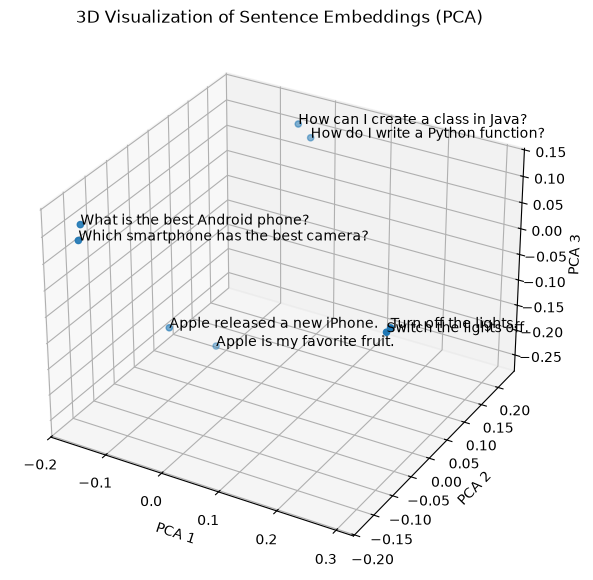

In [9]:

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    pca_df["x"],
    pca_df["y"],
    pca_df["z"]
)

for i, txt in enumerate(pca_df["text"]):
    ax.text(
        pca_df["x"][i],
        pca_df["y"][i],
        pca_df["z"][i],
        txt
    )

ax.set_title("3D Visualization of Sentence Embeddings (PCA)")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")

plt.show()



## 6. Interactive 3D Visualization Using Plotly

### Why Plotly?

Matplotlib provides a static visualization of our embeddings, whereas Plotly allows us to interact with the 3D representation.

Using Plotly, we can:

- Rotate the 3D plot to examine relationships from different angles.
- Zoom in and out.
- Hover over individual points.
- Explore how sentences are distributed in the PCA-reduced embedding space.

Each point represents one sentence, projected from 768 dimensions into 3 principal components.


In [10]:

import plotly.express as px

fig = px.scatter_3d(
    pca_df,
    x="x",
    y="y",
    z="z",
    text="text",
    title="3D Embedding Visualization",
    height=800,
    width=1100
)

fig.show()
